# Кластеризация ЕГЭ

Выполнены обе части задания: анализ пяти Excel-файлов и сравнение MiniBatch K-Means с DBSCAN.

## Часть 1. Кластеризация пяти наборов точек

Число кластеров определено по визуальному распределению точек: для файлов `0`–`4` использованы соответственно 2, 3, 2, 3 и 2 кластера. Для воспроизводимого назначения точек применён K-Means с этим числом кластеров. Центральная точка каждого кластера — медоид, то есть точка набора с минимальной суммой расстояний до остальных точек своего кластера.

**Метрика:** евклидова для файлов 0, 1 и 2; манхэттенская для файлов 3 и 4.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances

FILES = {
    "0": "/mnt/data/converted/0.xlsx",
    "1": "/mnt/data/converted/1.xlsx",
    "2": "/mnt/data/2.xlsx",
    "3": "/mnt/data/3.xlsx",
    "4": "/mnt/data/4.xlsx",
}
N_CLUSTERS = {"0": 2, "1": 3, "2": 2, "3": 3, "4": 2}

data = {}
for name, path in FILES.items():
    df = pd.read_excel(path)
    # В каждой таблице два столбца с координатами X и Y.
    points = df.iloc[:, :2].apply(pd.to_numeric, errors="coerce").dropna().to_numpy()
    data[name] = points
    print(f"Файл {name}: {len(points)} точек")

Файл 0: 100 точек


Файл 1: 9999 точек
Файл 2: 999 точек


Файл 3: 9999 точек
Файл 4: 500 точек


### 1. Распределения точек без кластеризации

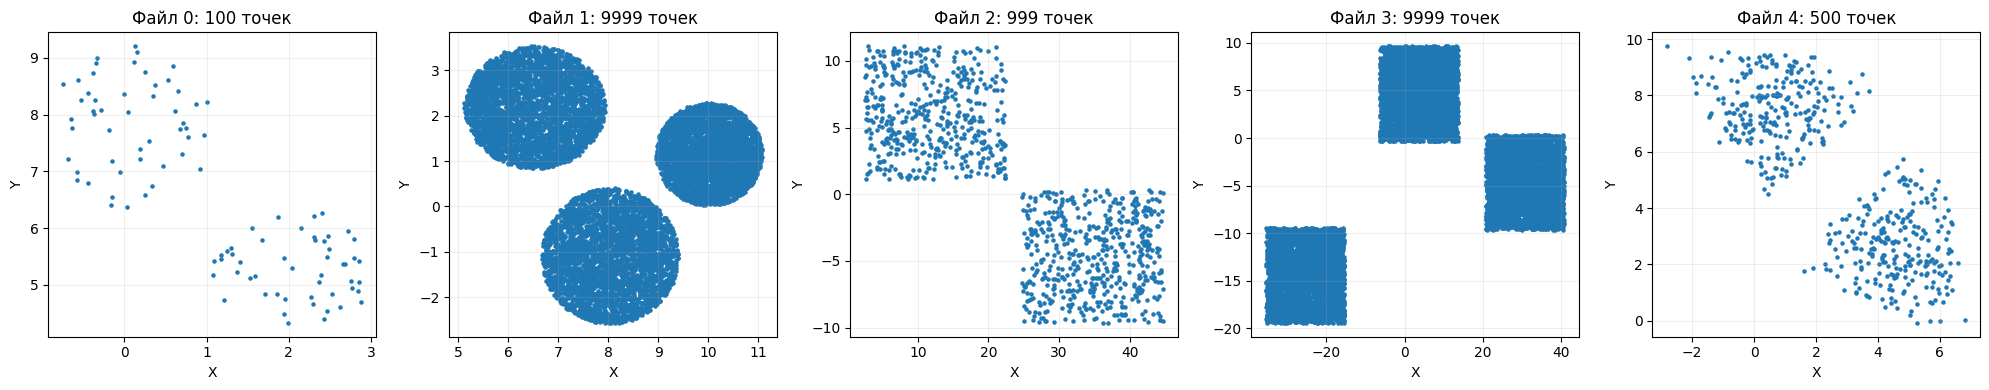

In [2]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (name, points) in zip(axes, data.items()):
    ax.scatter(points[:, 0], points[:, 1], s=5)
    ax.set_title(f"Файл {name}: {len(points)} точек")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 2–3. Выделение кластеров и графики с цветовой маркировкой

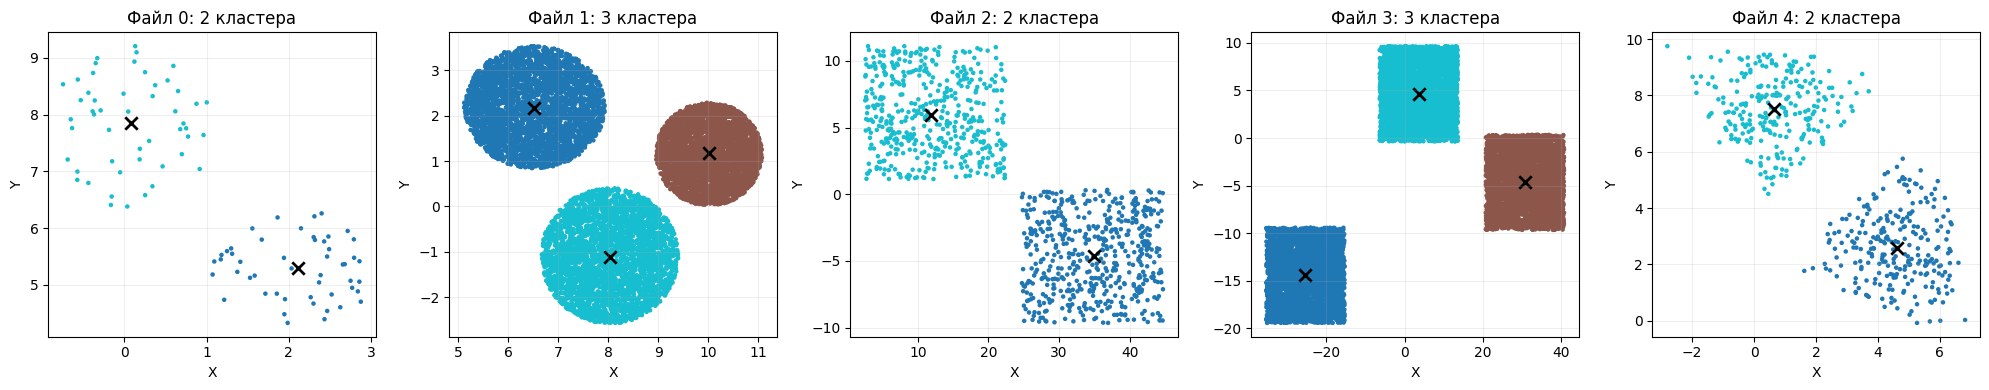

In [3]:
labels_by_file = {}
metric_by_file = {}
fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for ax, (name, points) in zip(axes, data.items()):
    k = N_CLUSTERS[name]
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(points)
    labels_by_file[name] = labels
    metric_by_file[name] = "manhattan" if name in {"3", "4"} else "euclidean"

    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap="tab10", s=5)
    centers = model.cluster_centers_
    ax.scatter(centers[:, 0], centers[:, 1], marker="x", c="black", s=80, linewidths=2)
    ax.set_title(f"Файл {name}: {k} кластера")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### 4–5. Центральные точки и усреднение центров кластеров

In [4]:
medoid_rows = []
all_cluster_centers = []

for name, points in data.items():
    labels = labels_by_file[name]
    metric = metric_by_file[name]
    for cluster_id in sorted(np.unique(labels)):
        cluster_points = points[labels == cluster_id]
        # Попарные расстояния внутри кластера согласно заданной метрике.
        distances = pairwise_distances(cluster_points, metric=metric)
        medoid_index = np.argmin(distances.sum(axis=1))
        medoid = cluster_points[medoid_index]
        center = cluster_points.mean(axis=0)
        all_cluster_centers.append(center)
        medoid_rows.append({
            "Файл": name,
            "Кластер": int(cluster_id) + 1,
            "Количество точек": len(cluster_points),
            "Метрика": metric,
            "X медоида": medoid[0],
            "Y медоида": medoid[1],
            "X центра": center[0],
            "Y центра": center[1],
        })

results = pd.DataFrame(medoid_rows)
display(results.round(6))

mean_center = np.mean(np.asarray(all_cluster_centers), axis=0)
print("Среднее координат центров всех кластеров, умноженное на 1000:")
print(f"X * 1000 = {mean_center[0] * 1000:.6f}")
print(f"Y * 1000 = {mean_center[1] * 1000:.6f}")

results.to_excel("results_part1.xlsx", index=False)
print("Таблица сохранена в results_part1.xlsx")

,Файл,Кластер,Количество точек,Метрика,X медоида,Y медоида,X центра,Y центра
0,0,1,50,euclidean,2.033901,5.289296,2.106680,5.298609
1,0,2,50,euclidean,0.048112,8.053051,0.080262,7.852814
2,1,1,3333,euclidean,6.469983,2.169761,6.512861,2.172365
3,1,2,3333,euclidean,10.022535,1.154201,10.018099,1.170246
4,1,3,3333,euclidean,8.040075,-1.108706,8.030649,-1.112156
5,2,1,524,euclidean,34.926351,-4.695276,34.976376,-4.616686
6,2,2,475,euclidean,11.334080,5.965961,11.799141,5.907972
7,3,1,3428,manhattan,-25.130758,-14.413328,-25.289394,-14.410901
8,3,2,3287,manhattan,30.849529,-4.517203,30.796696,-4.605101
9,3,3,3284,manhattan,3.517911,4.653696,3.605540,4.621564


Среднее координат центров всех кластеров, умноженное на 1000:
X * 1000 = 7324.928903
Y * 1000 = 1031.349039
Таблица сохранена в results_part1.xlsx


## Часть 2. Сравнение алгоритмов sklearn

Сравниваются MiniBatch K-Means и DBSCAN на шести стандартных наборах: `noisy_circles`, `noisy_moons`, `varied`, `aniso`, `blobs`, `no_structure`. Перед кластеризацией данные стандартизируются. Для K-Means задано ожидаемое число групп; параметры DBSCAN подобраны отдельно для каждого набора. Шум DBSCAN показывается отдельным цветом.

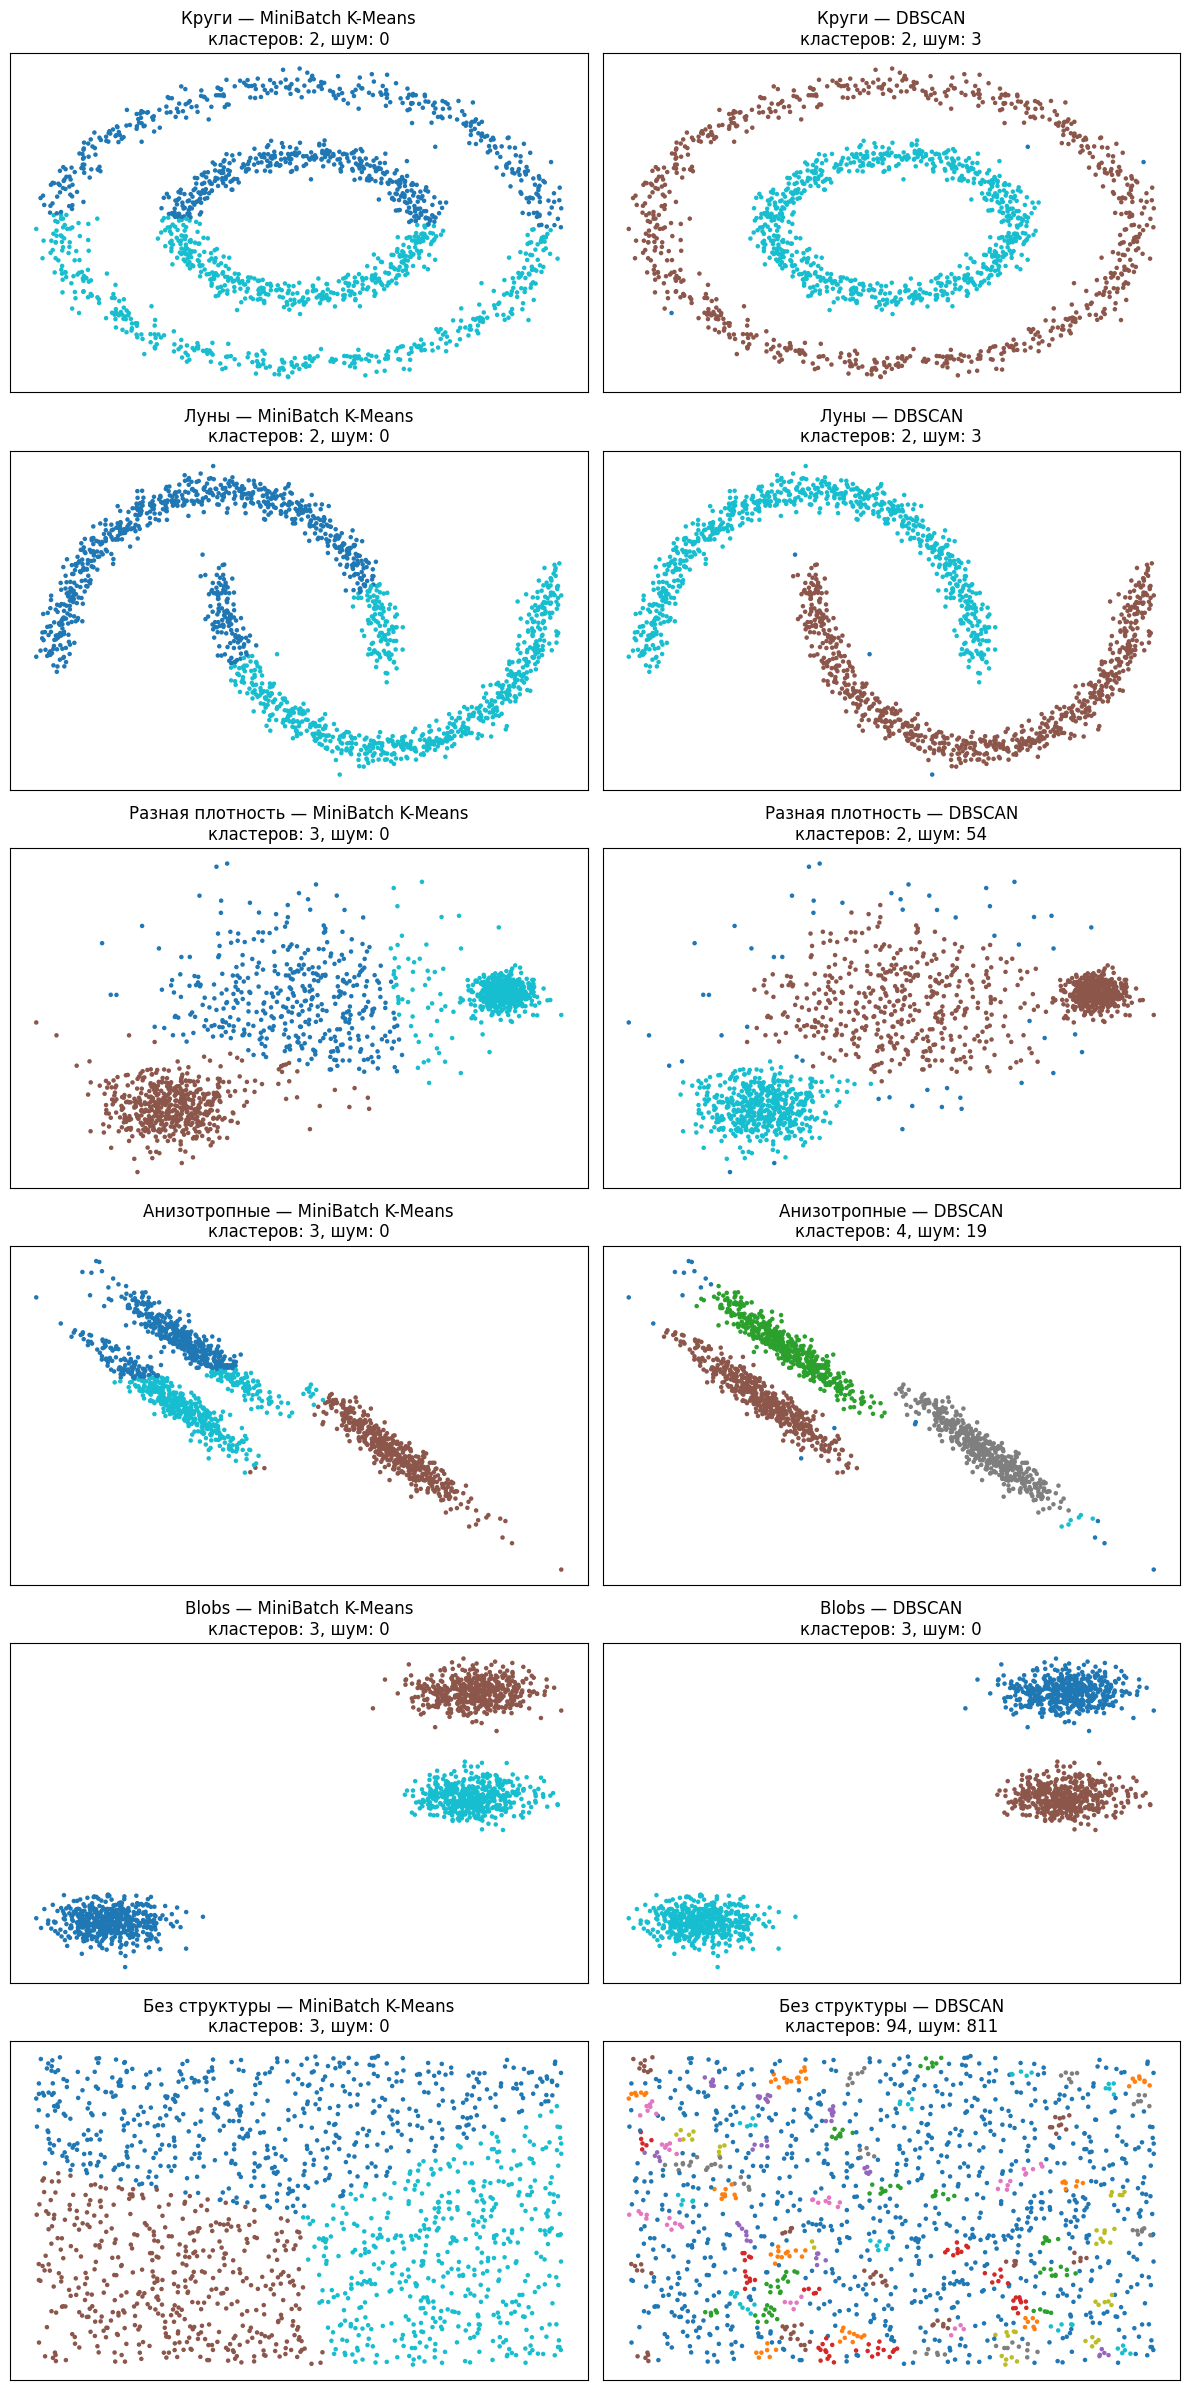

,Набор данных,Алгоритм,Число кластеров,Шумовых точек,"Время, сек"
0,Круги,MiniBatch K-Means,2,0,0.0057
1,Круги,DBSCAN,2,3,0.0081
2,Луны,MiniBatch K-Means,2,0,0.0059
3,Луны,DBSCAN,2,3,0.0057
4,Разная плотность,MiniBatch K-Means,3,0,0.0054
5,Разная плотность,DBSCAN,2,54,0.0087
6,Анизотропные,MiniBatch K-Means,3,0,0.0096
7,Анизотропные,DBSCAN,4,19,0.0071
8,Blobs,MiniBatch K-Means,3,0,0.0079
9,Blobs,DBSCAN,3,0,0.0127


Сводная таблица сохранена в results_part2.xlsx


In [5]:
import time
import warnings
from sklearn import cluster, datasets
from sklearn.preprocessing import StandardScaler

np.random.seed(0)
n_samples = 1500

noisy_circles = datasets.make_circles(n_samples=n_samples, factor=0.5, noise=0.05)
noisy_moons = datasets.make_moons(n_samples=n_samples, noise=0.05)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=8)
no_structure = (np.random.rand(n_samples, 2), None)

random_state = 170
X, y = datasets.make_blobs(n_samples=n_samples, random_state=random_state)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)
aniso = (X_aniso, y)

varied = datasets.make_blobs(
    n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=random_state
)

datasets_list = [
    ("Круги", noisy_circles, 2, 0.18, 5),
    ("Луны", noisy_moons, 2, 0.15, 5),
    ("Разная плотность", varied, 3, 0.18, 5),
    ("Анизотропные", aniso, 3, 0.15, 5),
    ("Blobs", blobs, 3, 0.25, 5),
    ("Без структуры", no_structure, 3, 0.08, 5),
]

algorithms = [
    ("MiniBatch K-Means", lambda k, eps, ms: cluster.MiniBatchKMeans(
        n_clusters=k, random_state=42, n_init=10, batch_size=256
    )),
    ("DBSCAN", lambda k, eps, ms: cluster.DBSCAN(eps=eps, min_samples=ms)),
]

fig, axes = plt.subplots(len(datasets_list), len(algorithms), figsize=(12, 24))
summary = []

for row, (dataset_name, (X, y), k, eps, min_samples) in enumerate(datasets_list):
    X_scaled = StandardScaler().fit_transform(X)

    for col, (algorithm_name, factory) in enumerate(algorithms):
        estimator = factory(k, eps, min_samples)
        start = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            predicted = estimator.fit_predict(X_scaled)
        elapsed = time.time() - start

        n_clusters_found = len(set(predicted)) - (1 if -1 in predicted else 0)
        n_noise = int(np.sum(predicted == -1))
        summary.append({
            "Набор данных": dataset_name,
            "Алгоритм": algorithm_name,
            "Число кластеров": n_clusters_found,
            "Шумовых точек": n_noise,
            "Время, сек": elapsed,
        })

        ax = axes[row, col]
        ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=predicted, cmap="tab10", s=5)
        ax.set_title(f"{dataset_name} — {algorithm_name}\n"
                     f"кластеров: {n_clusters_found}, шум: {n_noise}")
        ax.set_xticks([])
        ax.set_yticks([])

plt.tight_layout()
plt.show()

summary_df = pd.DataFrame(summary)
display(summary_df.round(4))
summary_df.to_excel("results_part2.xlsx", index=False)
print("Сводная таблица сохранена в results_part2.xlsx")

## Вывод

MiniBatch K-Means требует заранее задать число кластеров и хорошо подходит для компактных групп, но его границы обычно плохо соответствуют данным в форме колец и лун. DBSCAN не требует заранее задавать число кластеров, умеет находить группы произвольной формы и выделять шум, однако чувствителен к `eps` и `min_samples`; при разной плотности групп ему сложнее подобрать единый порог. Конкретные результаты и число найденных кластеров приведены в сводной таблице выше.